# Williams-Otto tanh Surrogate Optimization Benchmark

This notebook trains a `tanh` neural-network surrogate for the Williams-Otto steady-state benchmark, embeds the trained network into a Pyomo model through OMLT's exact smooth tanh formulation, and compares the surrogate optimum against the exact Williams-Otto model.

The embedded Pyomo model is solved with Ipopt when available. If Ipopt is not installed, the notebook still builds the embedded model and uses a SciPy surrogate-optimization fallback so the benchmark produces a concrete operating point.

In [1]:
from __future__ import annotations

import os
import sys
from pathlib import Path


def find_project_root(start):
    for candidate in (start, *start.parents):
        if (candidate / "src" / "pwlnet").exists() and (candidate / "pyproject.toml").exists():
            return candidate
    raise RuntimeError("Could not find the PWLNet project root from the notebook working directory.")


# Fallback for kernels without an editable `pip install -e .` of pwlnet.
ROOT = find_project_root(Path.cwd().resolve())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.ticker import LogLocator, LogFormatterSciNotation
import numpy as np
import pandas as pd

from pwlnet import PWLNet, metrics_table, train_val_test_split
from pwlnet.processes.williams_otto import (
    EXACT_OPTIMUM,
    INPUT_NAMES,
    OUTPUT_NAMES,
    WilliamsOttoParameters,
    build_surrogate_optimization_model,
    generate_dataset,
    profit,
    solve_steady_state,
    solve_surrogate_optimization_model,
)
from pwlnet.solvers import find_ipopt

params = WilliamsOttoParameters()

plt.style.use("seaborn-v0_8-whitegrid")


## Generate Williams-Otto data

The surrogate maps the two operating decisions, `FB` and `TR`, to six reactor mass fractions. The exact simulator is used to create supervised training data.

In [2]:
# Shared experiment configuration (identical across notebooks 01-03):
# 150 Latin-hypercube samples split 60/20/20 into train/validation/test
# with one fixed seed, so all three notebooks train and evaluate on the
# exact same partitions.
RANDOM_SEED = 7
DATA_CONFIG = dict(n_samples=150, method="lhs", random_state=RANDOM_SEED)
VAL_SIZE, TEST_SIZE = 0.2, 0.2

data = generate_dataset(**DATA_CONFIG, as_frame=True)
split = train_val_test_split(data, val_size=VAL_SIZE, test_size=TEST_SIZE, random_state=RANDOM_SEED)
train_df, val_df, test_df = split.train, split.validation, split.test


def split_xy(frame):
    return frame[INPUT_NAMES].to_numpy(dtype=float), frame[OUTPUT_NAMES].to_numpy(dtype=float)


X_train, y_train = split_xy(train_df)
X_val, y_val = split_xy(val_df)
X_test, y_test = split_xy(test_df)

# Dense regular 21x21 grid for landscape contour plots (pivot-based
# contouring needs a full mesh; the LHS samples are scattered).
plot_grid = generate_dataset(n_samples=441, method="grid", random_state=RANDOM_SEED, as_frame=True)

print(f"data: {len(data)} samples -> train {len(train_df)} / val {len(val_df)} / test {len(test_df)}")
data.head() # type: ignore


data: 150 samples -> train 90 / val 30 / test 30


,FB,TR,XA,XB,XC,XE,XG,XP,profit,residual_inf_norm
0,5.747498,77.420557,0.104888,0.511495,0.022780,0.221769,0.042276,0.096792,-24.799879,2.220446e-16
1,6.944486,80.554959,0.084438,0.564812,0.017969,0.205918,0.035855,0.091007,-95.868952,9.992007e-16
2,4.053997,89.025289,0.104188,0.329238,0.017761,0.307018,0.132429,0.109366,84.371330,7.616130e-14
3,6.439895,86.835754,0.074597,0.512648,0.014399,0.239701,0.058208,0.100448,1.033706,3.230749e-14
4,6.744059,85.506413,0.074986,0.534479,0.014853,0.228195,0.050086,0.097402,-30.859799,5.329071e-14


## Exact benchmark landscape

The contour plots show the exact Williams-Otto profit and the two operating constraint outputs over a dense 21x21 simulator grid (the scattered LHS training samples cannot be contoured directly).


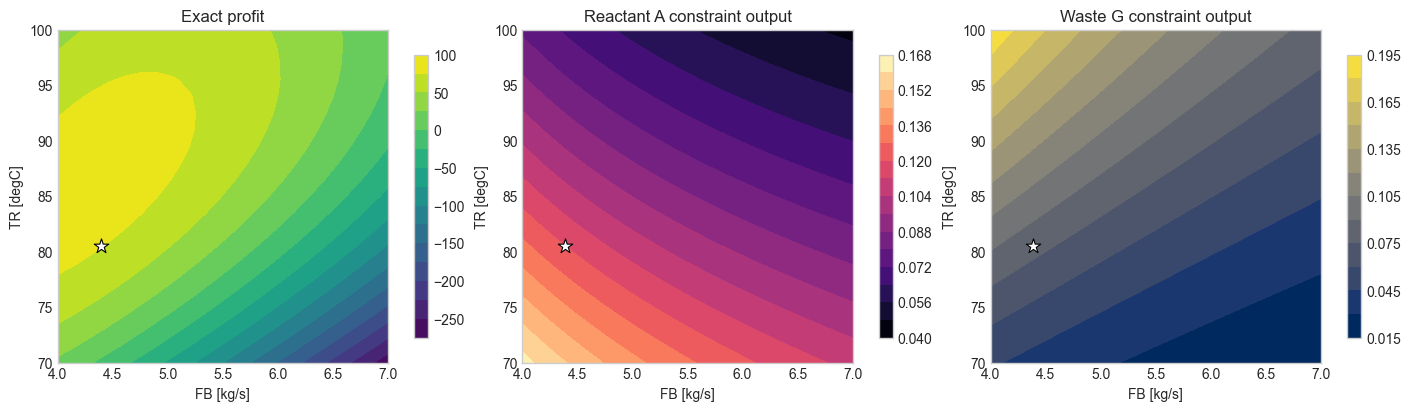

In [3]:
def grid_values(frame, column):
    table = frame.pivot(index="TR", columns="FB", values=column).sort_index()
    return table.columns.to_numpy(dtype=float), table.index.to_numpy(dtype=float), table.to_numpy(dtype=float)


fig, axes = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)
for ax, column, title, cmap in zip(
    axes,
    ["profit", "XA", "XG"],
    ["Exact profit", "Reactant A constraint output", "Waste G constraint output"],
    ["viridis", "magma", "cividis"],
):
    fb_grid, tr_grid, z = grid_values(plot_grid, column)
    contour = ax.contourf(fb_grid, tr_grid, z, levels=14, cmap=cmap)
    ax.scatter([EXACT_OPTIMUM["FB"]], [EXACT_OPTIMUM["TR"]], marker="*", s=120, color="white", edgecolor="black", linewidth=0.8)
    ax.set_title(title)
    ax.set_xlabel("FB [kg/s]")
    ax.set_ylabel("TR [degC]")
    fig.colorbar(contour, ax=ax, shrink=0.85)

plt.show()

## Train a tanh surrogate

This is still ordinary gradient-based training. The Phase-1 output is a framework-independent `NetworkDefinition` carrying the trained weights, scalers, and input bounds.

Because the operating constraints `XA <= 0.12` and `XG <= 0.08` are imposed on the surrogate's `XA` and `XG` outputs, the *accuracy of the learned constraint* depends entirely on how well those two outputs are fit. We therefore train with a **per-output weighted MSE** that penalizes errors in the two constraint-defining outputs `CONSTRAINT_WEIGHT`x more heavily than the remaining mass fractions, pulling the learned feasibility boundary closer to the exact one.

In [4]:
from pwlnet.training.initialization import import_keras
from pwlnet.training.keras_trainer import KerasTrainer

keras = import_keras()

# Penalize the two constraint-defining outputs (XA, XG) more heavily so the
# surrogate fits the feasibility boundary (XA <= 0.12, XG <= 0.08) more
# accurately than the unconstrained mass fractions. Training happens in
# standardized (unit-variance) output space, so each weight is the relative
# importance of that output's squared error: CONSTRAINT_WEIGHT makes a
# constraint-output error count that many times a normal-output error.
CONSTRAINT_OUTPUTS = ("XA", "XG")
CONSTRAINT_WEIGHT = 10.0
output_weights = np.ones(len(OUTPUT_NAMES))
for _name in CONSTRAINT_OUTPUTS:
    output_weights[OUTPUT_NAMES.index(_name)] = CONSTRAINT_WEIGHT


class WeightedOutputKerasTrainer(KerasTrainer):
    """KerasTrainer with a per-output weighted MSE loss.

    Reuses the base trainer's scaling, layer extraction, and Keras<->numpy
    equivalence check; only the compiled loss changes, so selected outputs
    are penalized more heavily during gradient descent.
    """

    def __init__(self, *args, output_weights=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.output_weights = (
            None if output_weights is None else np.asarray(output_weights, dtype=float)
        )

    def _build_model(self, keras_module, n_inputs, n_outputs):
        model = super()._build_model(keras_module, n_inputs, n_outputs)
        if self.output_weights is not None:
            weights = keras_module.ops.convert_to_tensor(self.output_weights, dtype="float32")

            def weighted_mse(y_true, y_pred):
                return keras_module.ops.mean(weights * keras_module.ops.square(y_true - y_pred))

            model.compile(optimizer=model.optimizer, loss=weighted_mse)
        return model


trainer = WeightedOutputKerasTrainer(
    hidden_layers=[8],
    activation="tanh",
    loss="mse",
    epochs=1000,
    batch_size=16,
    early_stopping_patience=25,
    random_seed=RANDOM_SEED,
    verbose=0,
    output_weights=output_weights,
)
net = PWLNet(trainer.fit(X_train, y_train, validation_data=(X_val, y_val)), trainer=trainer)

print(net.summary())
print(f"Keras-to-core max prediction difference: {net.trainer.equivalence_error_:.3e}")  # type: ignore
print(f"Per-output loss weights: {dict(zip(OUTPUT_NAMES, output_weights))}")

# Train/validation/test prediction quality (MAE, MSE, RMSE, R2).
metrics = metrics_table(
    {
        "train": (y_train, net.predict(X_train)),
        "validation": (y_val, net.predict(X_val)),
        "test": (y_test, net.predict(X_test)),
    }
)
metrics


NetworkDefinition: 2 inputs -> 6 outputs, 2 layers, 8 hidden neurons, 78 parameters
layer   n_in  n_out activation   params
    0      2      8       tanh       24
    1      8      6     linear       54
Keras-to-core max prediction difference: 1.305e-08
Per-output loss weights: {'XA': np.float64(10.0), 'XB': np.float64(1.0), 'XC': np.float64(1.0), 'XE': np.float64(1.0), 'XG': np.float64(10.0), 'XP': np.float64(1.0)}


,split,MAE,MSE,RMSE,R2,n_samples
0,train,0.000800,0.000002,0.001253,0.998886,90
1,validation,0.000864,0.000002,0.001362,0.998564,30
2,test,0.000880,0.000002,0.001477,0.998359,30


## Training diagnostics

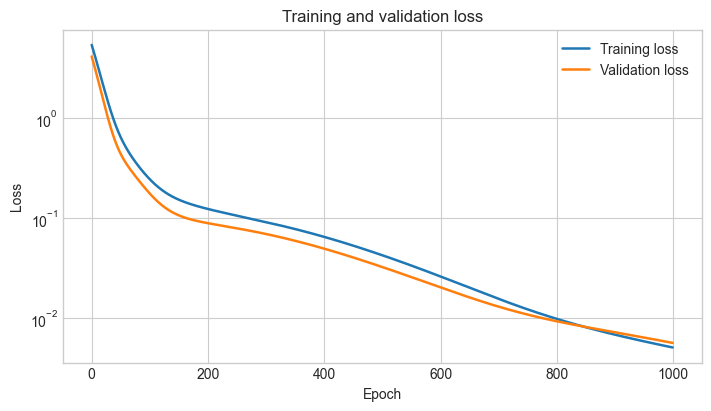

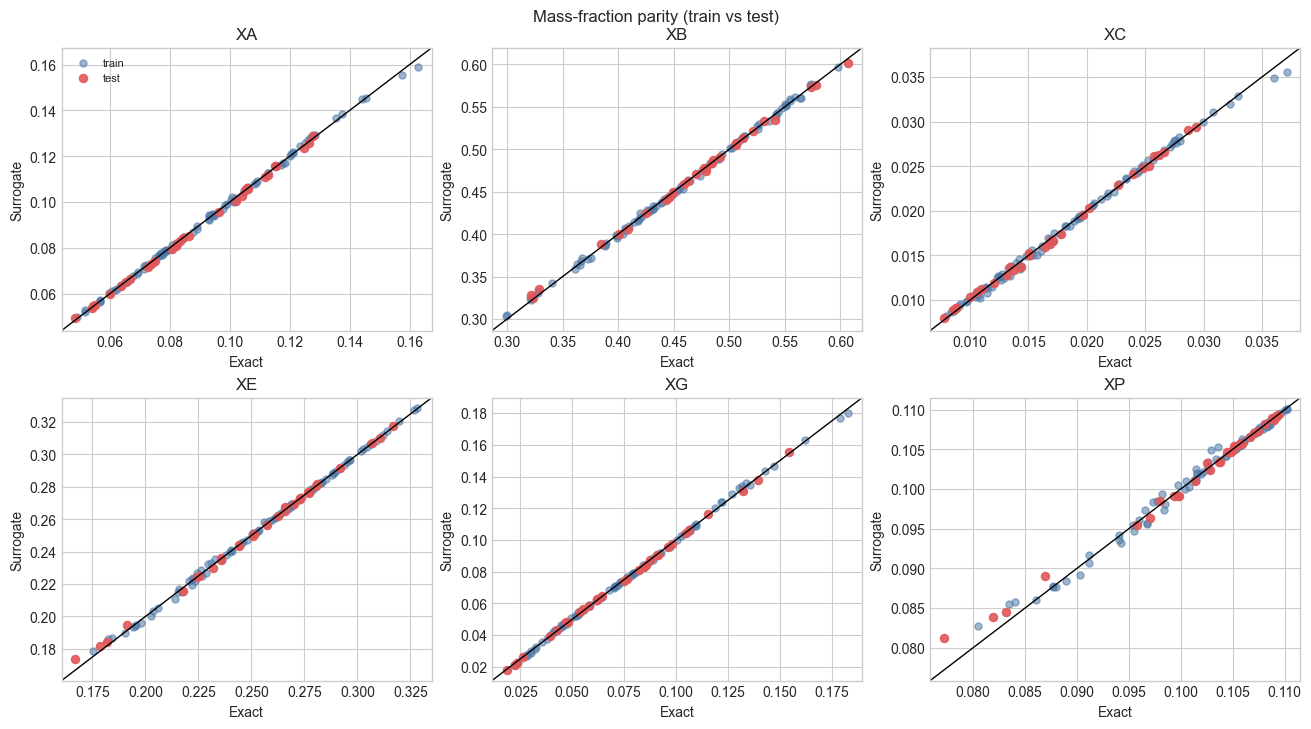

In [5]:
history = net.trainer.history_ or {}

fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
ax.plot(history.get("loss", []), linewidth=1.8, label="Training loss")
if "val_loss" in history:
    ax.plot(history["val_loss"], linewidth=1.8, label="Validation loss")
ax.set_title("Training and validation loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.set_yscale("log")
ax.legend()
plt.show()

pred_train = net.predict(X_train)
pred_test = net.predict(X_test)

fig, axes = plt.subplots(2, 3, figsize=(13, 7), constrained_layout=True)
for ax, name, j in zip(axes.ravel(), OUTPUT_NAMES, range(len(OUTPUT_NAMES))):
    ax.scatter(y_train[:, j], pred_train[:, j], s=26, alpha=0.55, color="#4e79a7", label="train")
    ax.scatter(y_test[:, j], pred_test[:, j], s=34, alpha=0.9, color="#e15759", label="test")
    cat = np.concatenate([y_train[:, j], y_test[:, j], pred_train[:, j], pred_test[:, j]])
    lo, hi = float(cat.min()), float(cat.max())
    pad = 0.04 * max(hi - lo, 1e-6)
    ax.plot([lo - pad, hi + pad], [lo - pad, hi + pad], color="black", linewidth=1.0)
    ax.set_xlim(lo - pad, hi + pad)
    ax.set_ylim(lo - pad, hi + pad)
    ax.set_title(name)
    ax.set_xlabel("Exact")
    ax.set_ylabel("Surrogate")
axes.ravel()[0].legend(loc="upper left", fontsize=8)
fig.suptitle("Mass-fraction parity (train vs test)", y=1.02)
plt.show()


## Surrogate-implied profit landscape

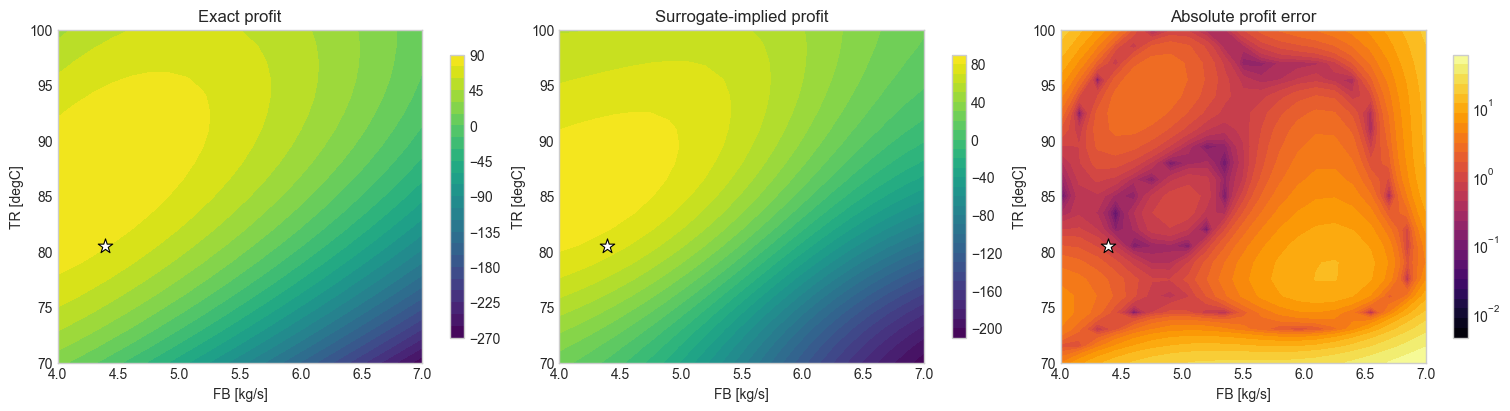

In [6]:
plot_data = plot_grid.copy()
pred_grid = net.predict(plot_data[INPUT_NAMES].to_numpy(dtype=float))
for i, name in enumerate(OUTPUT_NAMES):
    plot_data[f"{name}_pred"] = pred_grid[:, i]

flow = params.fa + plot_data["FB"].to_numpy(dtype=float)
plot_data["profit_pred"] = (
    (params.price_p * plot_data["XP_pred"].to_numpy(dtype=float)
     + params.price_e * plot_data["XE_pred"].to_numpy(dtype=float))
    * flow
    - params.cost_a * params.fa
    - params.cost_b * plot_data["FB"].to_numpy(dtype=float)
)
plot_data["profit_abs_error"] = np.abs(plot_data["profit_pred"] - plot_data["profit"])

fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)

for ax, column, title, cmap in zip(
    axes,
    ["profit", "profit_pred", "profit_abs_error"],
    ["Exact profit", "Surrogate-implied profit", "Absolute profit error"],
    ["viridis", "viridis", "inferno"],
):
    fb_grid, tr_grid, z = grid_values(plot_data, column)

    if column == "profit_abs_error":
        positive = z[np.isfinite(z) & (z > 0)]

        eps = positive.min() / 1 if positive.size else 1e-12
        z_plot = np.where(z > 0, z, eps)

        vmin = z_plot.min()
        vmax = z_plot.max()

        levels = np.logspace(np.log10(vmin), np.log10(vmax), 30)

        contour = ax.contourf(
            fb_grid,
            tr_grid,
            z_plot,
            levels=levels,
            cmap=cmap,
            norm=LogNorm(vmin=vmin, vmax=vmax)
        )

        cbar = fig.colorbar(contour, ax=ax, shrink=0.85)
        cbar.locator = LogLocator(base=10, numticks=20)
        cbar.formatter = LogFormatterSciNotation(base=10)
        cbar.update_ticks()

    else:
        contour = ax.contourf(
            fb_grid,
            tr_grid,
            z,
            levels=30,
            cmap=cmap
        )

        fig.colorbar(contour, ax=ax, shrink=0.85)

    ax.scatter(
        [EXACT_OPTIMUM["FB"]],
        [EXACT_OPTIMUM["TR"]],
        marker="*",
        s=120,
        color="white",
        edgecolor="black",
        linewidth=0.8
    )

    ax.set_title(title)
    ax.set_xlabel("FB [kg/s]")
    ax.set_ylabel("TR [degC]")

plt.show()

## Build the embedded exact-tanh Pyomo model

The model below links the trained neural-network inputs to Williams-Otto decisions and uses OMLT's smooth exact tanh formulation for the hidden activations. This is an NLP embedding, not yet a Phase-2 PWL approximation.

In [7]:
embedded_model, embedded_block = build_surrogate_optimization_model(
    net.network,
    formulation="tanh_exact",
    params=params,
    profit_formulation="bilinear",
)

import pyomo.environ as pyo

n_vars = sum(1 for _ in embedded_model.component_data_objects(pyo.Var, descend_into=True))
n_cons = sum(1 for _ in embedded_model.component_data_objects(pyo.Constraint, active=True, descend_into=True))

print(f"embedded inputs: {len(list(embedded_block.inputs.keys()))}")
print(f"embedded outputs: {len(list(embedded_block.outputs.keys()))}")
print(f"Pyomo variables: {n_vars}")
print(f"Pyomo constraints: {n_cons}")

embedded inputs: 2
embedded outputs: 6
Pyomo variables: 48
Pyomo constraints: 60


## Optimize the embedded surrogate

If Ipopt is available, the embedded Pyomo NLP is solved directly. Otherwise, a SciPy fallback optimizes the same trained surrogate as a black-box objective with penalties for surrogate constraint violations. The fallback is included so the notebook remains executable on machines without Ipopt.

In [8]:
def surrogate_outputs(fb: float, tr: float) -> dict[str, float]:
    values = net.predict(np.array([[fb, tr]], dtype=float))[0]
    return {name: float(value) for name, value in zip(OUTPUT_NAMES, values)}


def surrogate_profit(outputs: dict[str, float], fb: float) -> float:
    return profit(outputs, fb, params=params)


def surrogate_violation(outputs: dict[str, float]) -> float:
    violations = []
    for name in OUTPUT_NAMES:
        value = outputs[name]
        violations.append(max(0.0, -value))
        violations.append(max(0.0, value - 1.0))
    violations.append(max(0.0, outputs["XA"] - params.xa_max))
    violations.append(max(0.0, outputs["XG"] - params.xg_max))
    return float(sum(v * v for v in violations))


def optimize_with_scipy():
    from scipy.optimize import differential_evolution, minimize

    bounds = [params.fb_bounds, params.tr_bounds]

    def objective(x):
        fb, tr = map(float, x)
        outputs = surrogate_outputs(fb, tr)
        return -surrogate_profit(outputs, fb)

    def penalized_objective(x):
        fb, tr = map(float, x)
        outputs = surrogate_outputs(fb, tr)
        return objective(x) + 1.0e10 * surrogate_violation(outputs)

    constraints = []
    for output_name in OUTPUT_NAMES:
        constraints.append({"type": "ineq", "fun": lambda x, name=output_name: surrogate_outputs(float(x[0]), float(x[1]))[name]})
        constraints.append({"type": "ineq", "fun": lambda x, name=output_name: 1.0 - surrogate_outputs(float(x[0]), float(x[1]))[name]})
    constraints.append({"type": "ineq", "fun": lambda x: params.xa_max - surrogate_outputs(float(x[0]), float(x[1]))["XA"]})
    constraints.append({"type": "ineq", "fun": lambda x: params.xg_max - surrogate_outputs(float(x[0]), float(x[1]))["XG"]})

    de_result = differential_evolution(
        penalized_objective,
        bounds=bounds,
        seed=RANDOM_SEED,
        polish=False,
        tol=1e-7,
        updating="immediate",
    )
    local_result = minimize(
        objective,
        de_result.x,
        method="SLSQP",
        bounds=bounds,
        constraints=constraints,
        options={"maxiter": 500, "ftol": 1e-10},
    )
    x_best = local_result.x if local_result.success else de_result.x
    fb, tr = map(float, x_best)
    outputs = surrogate_outputs(fb, tr)
    return {
        "method": "scipy_constrained_fallback" if local_result.success else "scipy_penalty_fallback",
        "termination": local_result.message if local_result.success else de_result.message,
        "FB": fb,
        "TR": tr,
        "predicted_outputs": outputs,
        "surrogate_profit": surrogate_profit(outputs, fb),
    }


ipopt = find_ipopt()
if ipopt is not None:
    result = solve_surrogate_optimization_model(
        net.network,
        formulation="tanh_exact",
        solver="ipopt",
        executable=ipopt,
        params=params,
        profit_formulation="bilinear",
    )
    optimization_result = {
        "method": "pyomo_omlt_ipopt",
        "termination": result.termination_condition,
        "FB": result.fb,
        "TR": result.tr,
        "predicted_outputs": result.predicted_outputs,
        "surrogate_profit": result.surrogate_profit,
    }
else:
    optimization_result = optimize_with_scipy()

optimization_result

{'method': 'pyomo_omlt_ipopt',
 'termination': 'optimal',
 'FB': 4.387086009018408,
 'TR': 80.59756061682496,
 'predicted_outputs': {'XA': 0.11993666887833328,
  'XB': 0.3971246949914339,
  'XC': 0.02377207679332374,
  'XE': 0.27120798297316745,
  'XG': 0.08000000994155143,
  'XP': 0.10860485734214594},
 'surrogate_profit': 75.5118068477708}

## Compare against the exact Williams-Otto benchmark

The comparison checks three cases: the known exact benchmark optimum, the surrogate optimum, and the exact simulator evaluated at the surrogate optimum.

In [9]:
FEASIBILITY_TOL = 1e-5

fb_star = optimization_result["FB"]
tr_star = optimization_result["TR"]
predicted = optimization_result["predicted_outputs"]
exact_at_surrogate = solve_steady_state(fb_star, tr_star, params=params)
exact_outputs = {name: float(value) for name, value in zip(OUTPUT_NAMES, exact_at_surrogate.x)}

comparison = pd.DataFrame(
    [
        {
            "case": "known exact optimum",
            "method": "reference",
            "FB": EXACT_OPTIMUM["FB"],
            "TR": EXACT_OPTIMUM["TR"],
            "profit": EXACT_OPTIMUM["profit"],
            "XA": 0.12,
            "XG": 0.08,
            "feasible": True,
        },
        {
            "case": "tanh surrogate optimum",
            "method": optimization_result["method"],
            "FB": fb_star,
            "TR": tr_star,
            "profit": optimization_result["surrogate_profit"],
            "XA": predicted["XA"],
            "XG": predicted["XG"],
            "feasible": predicted["XA"] <= params.xa_max + FEASIBILITY_TOL and predicted["XG"] <= params.xg_max + FEASIBILITY_TOL,
        },
        {
            "case": "exact at surrogate optimum",
            "method": "exact simulator",
            "FB": fb_star,
            "TR": tr_star,
            "profit": exact_at_surrogate.profit,
            "XA": exact_outputs["XA"],
            "XG": exact_outputs["XG"],
            "feasible": exact_outputs["XA"] <= params.xa_max + FEASIBILITY_TOL and exact_outputs["XG"] <= params.xg_max + FEASIBILITY_TOL,
        },
    ]
)

comparison

,case,method,FB,TR,profit,XA,XG,feasible
0,known exact optimum,reference,4.389400,80.495000,75.820000,0.120000,0.080000,True
1,tanh surrogate optimum,pyomo_omlt_ipopt,4.387086,80.597561,75.511807,0.119937,0.080000,True
2,exact at surrogate optimum,exact simulator,4.387086,80.597561,76.280729,0.119753,0.080506,False


## Optimization comparison plots

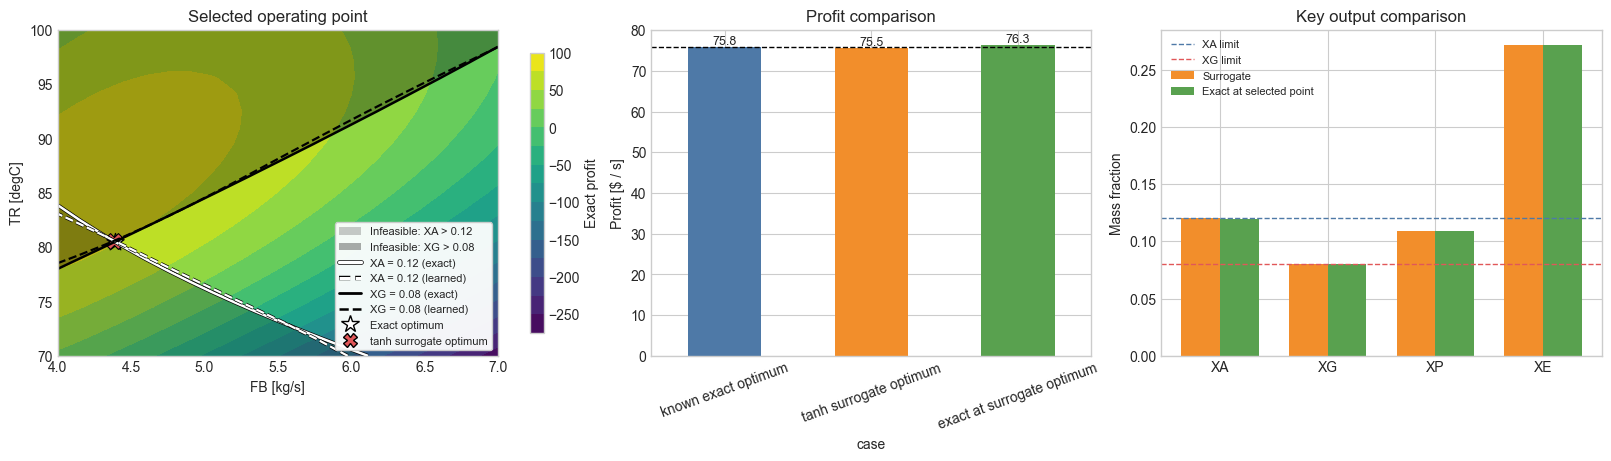

In [10]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import matplotlib.patheffects as pe

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)

fb_grid, tr_grid, exact_profit_grid = grid_values(plot_data, "profit")
_, _, xa_grid = grid_values(plot_data, "XA")
_, _, xg_grid = grid_values(plot_data, "XG")
# Learned (surrogate-predicted) constraint outputs over the same grid.
_, _, xa_pred_grid = grid_values(plot_data, "XA_pred")
_, _, xg_pred_grid = grid_values(plot_data, "XG_pred")

contour = axes[0].contourf(fb_grid, tr_grid, exact_profit_grid, levels=16, cmap="viridis")
xa_upper = float(np.nanmax(xa_grid))
xg_upper = float(np.nanmax(xg_grid))
if xa_upper > params.xa_max:
    axes[0].contourf(
        fb_grid,
        tr_grid,
        xa_grid,
        levels=[params.xa_max, xa_upper],
        colors=["#171717"],
        alpha=0.22,
        antialiased=True,
    )
if xg_upper > params.xg_max:
    axes[0].contourf(
        fb_grid,
        tr_grid,
        xg_grid,
        levels=[params.xg_max, xg_upper],
        colors=["#000000"],
        alpha=0.32,
        antialiased=True,
    )
xa_line = axes[0].contour(
    fb_grid,
    tr_grid,
    xa_grid,
    levels=[params.xa_max],
    colors="white",
    linewidths=1.8,
)
xg_line = axes[0].contour(
    fb_grid,
    tr_grid,
    xg_grid,
    levels=[params.xg_max],
    colors="black",
    linewidths=1.8,
)
xa_line.set_path_effects([pe.Stroke(linewidth=2.8, foreground="black"), pe.Normal()])
# Learned constraint boundaries (dashed) vs the exact ones (solid): the
# closer the dashed curve hugs the solid one, the better the surrogate
# learned that operating constraint.
xa_learned = axes[0].contour(
    fb_grid,
    tr_grid,
    xa_pred_grid,
    levels=[params.xa_max],
    colors="white",
    linewidths=1.6,
    linestyles="--",
)
xa_learned.set_path_effects([pe.Stroke(linewidth=2.6, foreground="black"), pe.Normal()])
axes[0].contour(
    fb_grid,
    tr_grid,
    xg_pred_grid,
    levels=[params.xg_max],
    colors="black",
    linewidths=1.6,
    linestyles="--",
)
axes[0].scatter([EXACT_OPTIMUM["FB"]], [EXACT_OPTIMUM["TR"]], marker="*", s=170, color="white", edgecolor="black", linewidth=0.9)
axes[0].scatter([fb_star], [tr_star], marker="X", s=130, color="#e15759", edgecolor="black", linewidth=0.8)
axes[0].set_title("Selected operating point")
axes[0].set_xlabel("FB [kg/s]")
axes[0].set_ylabel("TR [degC]")
fig.colorbar(contour, ax=axes[0], shrink=0.86, label="Exact profit")

legend_handles = [
    Patch(facecolor="#171717", alpha=0.22, label="Infeasible: XA > 0.12"),
    Patch(facecolor="#000000", alpha=0.32, label="Infeasible: XG > 0.08"),
    Line2D([0], [0], color="white", lw=2.4, label="XA = 0.12 (exact)", path_effects=[pe.Stroke(linewidth=3.4, foreground="black"), pe.Normal()]),
    Line2D([0], [0], color="white", lw=2.2, linestyle="--", label="XA = 0.12 (learned)", path_effects=[pe.Stroke(linewidth=3.2, foreground="black"), pe.Normal()]),
    Line2D([0], [0], color="black", lw=2.0, label="XG = 0.08 (exact)"),
    Line2D([0], [0], color="black", lw=1.8, linestyle="--", label="XG = 0.08 (learned)"),
    Line2D([0], [0], marker="*", color="white", markeredgecolor="black", markersize=13, linestyle="None", label="Exact optimum"),
    Line2D([0], [0], marker="X", color="#e15759", markeredgecolor="black", markersize=10, linestyle="None", label="tanh surrogate optimum"),
]
axes[0].legend(handles=legend_handles, loc="lower right", frameon=True, framealpha=0.95, fontsize=8)

profit_bars = comparison.set_index("case")["profit"]
colors = ["#4e79a7", "#f28e2b", "#59a14f"]
profit_bars.plot(kind="bar", ax=axes[1], color=colors, rot=20)
axes[1].set_title("Profit comparison")
axes[1].set_ylabel("Profit [$ / s]")
axes[1].axhline(EXACT_OPTIMUM["profit"], color="black", linestyle="--", linewidth=1.0)
for patch in axes[1].patches:
    height = patch.get_height()
    axes[1].annotate(f"{height:.1f}", (patch.get_x() + patch.get_width() / 2, height), ha="center", va="bottom", fontsize=9)

output_names = ["XA", "XG", "XP", "XE"]
x = np.arange(len(output_names))
width = 0.36
axes[2].bar(x - width / 2, [predicted[name] for name in output_names], width, label="Surrogate", color="#f28e2b")
axes[2].bar(x + width / 2, [exact_outputs[name] for name in output_names], width, label="Exact at selected point", color="#59a14f")
axes[2].axhline(params.xa_max, color="#4e79a7", linestyle="--", linewidth=1.0, label="XA limit")
axes[2].axhline(params.xg_max, color="#e15759", linestyle="--", linewidth=1.0, label="XG limit")
axes[2].set_xticks(x)
axes[2].set_xticklabels(output_names)
axes[2].set_title("Key output comparison")
axes[2].set_ylabel("Mass fraction")
axes[2].legend(fontsize=8)

plt.show()

## Prediction detail at the selected point

In [11]:
pd.DataFrame(
    {
        "output": OUTPUT_NAMES,
        "surrogate": [predicted[name] for name in OUTPUT_NAMES],
        "exact": [exact_outputs[name] for name in OUTPUT_NAMES],
        "abs_error": [abs(predicted[name] - exact_outputs[name]) for name in OUTPUT_NAMES],
    }
)

,output,surrogate,exact,abs_error
0,XA,0.119937,0.119753,0.000184
1,XB,0.397125,0.396060,0.001064
2,XC,0.023772,0.023835,0.000063
3,XE,0.271208,0.271121,0.000087
4,XG,0.080000,0.080506,0.000506
5,XP,0.108605,0.108725,0.000120


## Notes

This notebook uses the exact smooth OMLT tanh embedding available from Phase 1. Phase 2 will replace that exact tanh block with a manual PWL-tanh block so the same benchmark can be solved as a MILP/MIQP/MISOCP-style optimization problem instead of an NLP.

## Operating constraints: constrained vs unconstrained

All three embedding methods in this benchmark suite express the surrogate
outputs as decision variables of the Pyomo model, so the Williams-Otto
operating constraints `XA <= 0.12` and `XG <= 0.08` are **linear constraints
on those output variables**. They can therefore be added to every method:

| method | embedding | problem class with XA/XG limits |
|---|---|---|
| ReLU big-M | OMLT `relu_bigm` | MILP |
| exact tanh | OMLT `tanh_exact` | NLP |
| PWL-tanh big-M | `tanh_pwl_bigm` | MILP |

Below we solve the embedded problem **without** the operating constraints
(pure profit maximization) and **with** them, then compare the selected
operating points and the solver time.

In [12]:
ipopt_path = find_ipopt()
assert ipopt_path is not None, "Ipopt is required for the exact-tanh NLP comparison."

con = solve_surrogate_optimization_model(
    net.network, include_operating_constraints=True, params=params, formulation="tanh_exact", solver="ipopt", executable=ipopt_path, profit_formulation="bilinear"
)
unc = solve_surrogate_optimization_model(
    net.network, include_operating_constraints=False, params=params, formulation="tanh_exact", solver="ipopt", executable=ipopt_path, profit_formulation="bilinear"
)


def _constraint_row(case, r):
    return {
        "case": case,
        "FB": r.fb,
        "TR": r.tr,
        "surrogate profit": r.surrogate_profit,
        "true profit": r.exact_profit,
        "XA": r.predicted_outputs["XA"],
        "XG": r.predicted_outputs["XG"],
        "true feasible": r.exact_feasible,
        "solve time [s]": r.solve_seconds,
    }


constraint_table = pd.DataFrame(
    [
        _constraint_row("unconstrained", unc),
        _constraint_row("constrained (XA<=0.12, XG<=0.08)", con),
    ]
)
constraint_table

,case,FB,TR,surrogate profit,true profit,XA,XG,true feasible,solve time [s]
0,unconstrained,4.077038,85.173427,88.186109,88.511518,0.112702,0.109754,False,0.042846
1,"constrained (XA<=0.12, XG<=0.08)",4.387086,80.597561,75.511807,76.280729,0.119937,0.080000,False,0.050440


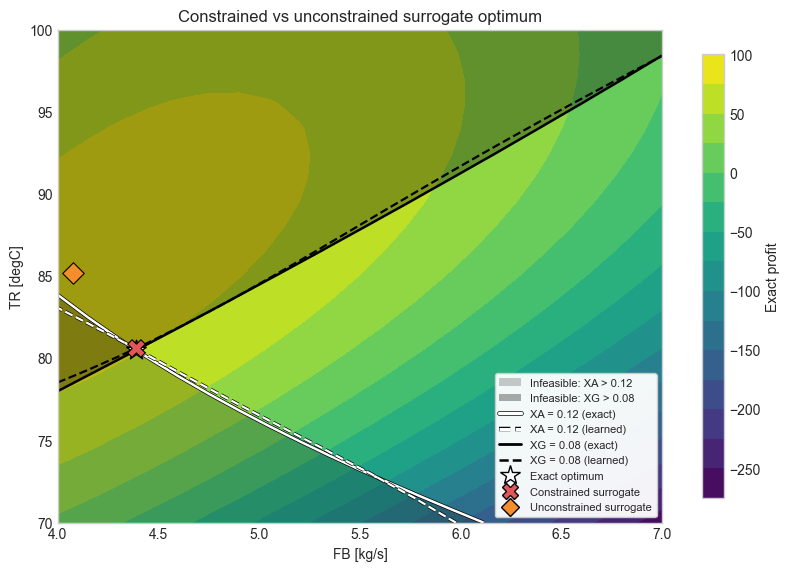

In [13]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import matplotlib.patheffects as pe

fig, ax = plt.subplots(figsize=(7.8, 5.6), constrained_layout=True)

fb_grid, tr_grid, profit_grid = grid_values(plot_data, "profit")
_, _, xa_grid = grid_values(plot_data, "XA")
_, _, xg_grid = grid_values(plot_data, "XG")
# Learned (surrogate-predicted) constraint outputs over the same grid.
_, _, xa_pred_grid = grid_values(plot_data, "XA_pred")
_, _, xg_pred_grid = grid_values(plot_data, "XG_pred")

contour = ax.contourf(fb_grid, tr_grid, profit_grid, levels=16, cmap="viridis")
xa_upper = float(np.nanmax(xa_grid))
xg_upper = float(np.nanmax(xg_grid))
if xa_upper > params.xa_max:
    ax.contourf(fb_grid, tr_grid, xa_grid, levels=[params.xa_max, xa_upper], colors=["#171717"], alpha=0.22, antialiased=True)
if xg_upper > params.xg_max:
    ax.contourf(fb_grid, tr_grid, xg_grid, levels=[params.xg_max, xg_upper], colors=["#000000"], alpha=0.32, antialiased=True)
xa_line = ax.contour(fb_grid, tr_grid, xa_grid, levels=[params.xa_max], colors="white", linewidths=1.8)
ax.contour(fb_grid, tr_grid, xg_grid, levels=[params.xg_max], colors="black", linewidths=1.8)
xa_line.set_path_effects([pe.Stroke(linewidth=2.8, foreground="black"), pe.Normal()])
# Learned constraint boundaries (dashed) overlaid on the exact ones (solid).
xa_learned = ax.contour(fb_grid, tr_grid, xa_pred_grid, levels=[params.xa_max], colors="white", linewidths=1.6, linestyles="--")
xa_learned.set_path_effects([pe.Stroke(linewidth=2.6, foreground="black"), pe.Normal()])
ax.contour(fb_grid, tr_grid, xg_pred_grid, levels=[params.xg_max], colors="black", linewidths=1.6, linestyles="--")

ax.scatter([con.exact_optimum["FB"]], [con.exact_optimum["TR"]], marker="*", s=220, color="white", edgecolor="black", linewidth=1.0, zorder=6)
ax.scatter([con.fb], [con.tr], marker="X", s=160, color="#e15759", edgecolor="black", linewidth=0.8, zorder=6)
ax.scatter([unc.fb], [unc.tr], marker="D", s=120, color="#f28e2b", edgecolor="black", linewidth=0.8, zorder=6)

ax.set_title("Constrained vs unconstrained surrogate optimum")
ax.set_xlabel("FB [kg/s]")
ax.set_ylabel("TR [degC]")
fig.colorbar(contour, ax=ax, shrink=0.9, label="Exact profit")

legend_handles = [
    Patch(facecolor="#171717", alpha=0.22, label="Infeasible: XA > 0.12"),
    Patch(facecolor="#000000", alpha=0.32, label="Infeasible: XG > 0.08"),
    Line2D([0], [0], color="white", lw=2.4, label="XA = 0.12 (exact)", path_effects=[pe.Stroke(linewidth=3.4, foreground="black"), pe.Normal()]),
    Line2D([0], [0], color="white", lw=2.2, linestyle="--", label="XA = 0.12 (learned)", path_effects=[pe.Stroke(linewidth=3.2, foreground="black"), pe.Normal()]),
    Line2D([0], [0], color="black", lw=2.0, label="XG = 0.08 (exact)"),
    Line2D([0], [0], color="black", lw=1.8, linestyle="--", label="XG = 0.08 (learned)"),
    Line2D([0], [0], marker="*", color="white", markeredgecolor="black", markersize=15, linestyle="None", label="Exact optimum"),
    Line2D([0], [0], marker="X", color="#e15759", markeredgecolor="black", markersize=11, linestyle="None", label="Constrained surrogate"),
    Line2D([0], [0], marker="D", color="#f28e2b", markeredgecolor="black", markersize=9, linestyle="None", label="Unconstrained surrogate"),
]
ax.legend(handles=legend_handles, loc="lower right", frameon=True, framealpha=0.95, fontsize=8)

plt.show()